# FlashPoint HexShape — detector-structure comparison

This notebook automatically scans

`/Volumes/ExtremeSSD/Software/FlashPointHexShape/run/BulkProduction/output_edge*_center*_reco`

and compares reconstruction performance for different **edge SiPM** and **central SiPM** layouts.

Main comparisons:
- total SiPM channels vs. $\sigma_{xy}$;
- relative position resolution $\sigma_{xy}/L$;
- edge/center configuration heatmaps;
- edge-SiPM and center-SiPM trends;
- detector timing-jitter scans;
- optional visual comparison of the saved spatial-resolution maps.

For the regular hexagon the default reference length is the **vertex-to-vertex diagonal**
$L=2R=2\times620.4=1240.8$ mm.

In [2]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("/Volumes/ExtremeSSD/Software/FlashPointHexShape/run/BulkProduction")
OUT  = BASE / "comparison_summary"
OUT.mkdir(exist_ok=True)

# Add once near the configuration section
FONT, TICK, LEGEND = 16, 14, 13

BEST_METHOD = "A + t1+t2+t3 ExtraTrees"

# Geometry
HEX_R_MM = 620.4
HEX_AREA=3*np.sqrt(3)/2*HEX_R_MM**2
REFERENCE_LENGTH_MM=np.sqrt(HEX_AREA)   # ~1000 mm for this geometry
# REFERENCE_LENGTH_MM = 2 * HEX_R_MM       # vertex-to-vertex diagonal = 1240.8 mm
N_VERTEX_SIPM = 6                        # one SiPM at each hexagon vertex
CENTER_COUNTS = {0:0, 2:1, 3:6, 4:7, 5:12, 6:13}

print(f"BASE = {BASE}")
print(f"Reference length = {REFERENCE_LENGTH_MM:.1f} mm")

BASE = /Volumes/ExtremeSSD/Software/FlashPointHexShape/run/BulkProduction
Reference length = 1000.0 mm


## 1. Discover all reconstructed configurations

For this geometry,
$$
N_\mathrm{SiPM}=6+6N_\mathrm{edge}+N_\mathrm{center}.
$$

Thus `edge1_center0` has 12 channels: 6 vertices + 6 edge SiPMs.

In [3]:
pat = re.compile(r"output_edge(\d+)_center(\d+)_reco$")

configs = []
for d in sorted(BASE.glob("output_edge*_center*_reco")):
    m = pat.match(d.name)
    if not m: continue
    edge, center = map(int, m.groups())
    nc = CENTER_COUNTS.get(center, np.nan)
    ns = N_VERTEX_SIPM + 6*edge + nc if np.isfinite(nc) else np.nan
    configs.append(dict(folder=d, edge=edge, center=center,
                        n_center=nc, n_sipm=ns, config=f"E{edge}-C{center}"))

cfg = pd.DataFrame(configs)
if cfg.empty:
    raise FileNotFoundError(f"No output_edge*_center*_reco folders found under {BASE}")

display(cfg.drop(columns="folder").sort_values(["n_sipm","edge","center"]).reset_index(drop=True))

,edge,center,n_center,n_sipm,config
0,0,0,0,6,E0-C0
1,1,0,0,12,E1-C0
2,1,2,1,13,E1-C2
3,1,3,6,18,E1-C3
4,2,0,0,18,E2-C0
5,1,4,7,19,E1-C4
6,1,5,12,24,E1-C5
7,3,0,0,24,E3-C0
8,1,6,13,25,E1-C6
9,2,6,13,31,E2-C6


## 2. Read reconstruction summaries robustly

In [4]:
def read_csv_clean(path):
    try:
        return pd.read_csv(path)
    except Exception as e:
        warnings.warn(f"Cannot read {path}: {e}")
        return None

def find_file(folder, names):
    for n in names:
        p = folder/n
        if p.exists() and not p.name.startswith("._"): return p
    return None

def first_col(df, names):
    if df is None: return None
    low = {c.lower(): c for c in df.columns}
    for n in names:
        if n.lower() in low: return low[n.lower()]
    return None

def numeric(row, names):
    for n in names:
        if n in row.index:
            try: return float(row[n])
            except: pass
    return np.nan

rows, all_methods = [], {}
for c in configs:
    f = find_file(c["folder"], ["spatiotemporal_reconstruction_summary.csv",
                                "reconstruction_summary.csv"])
    df = read_csv_clean(f) if f else None
    if df is None or df.empty:
        warnings.warn(f"No reconstruction summary: {c['folder'].name}")
        continue

    all_methods[c["config"]] = df.copy()
    mcol = first_col(df, ["method","name"])
    if mcol and (df[mcol].astype(str) == BEST_METHOD).any():
        r = df.loc[df[mcol].astype(str) == BEST_METHOD].iloc[0]
    else:
        r = df.iloc[0]
        warnings.warn(f"{c['config']}: '{BEST_METHOD}' not found; using first row.")

    sx = numeric(r, ["sigma_x_mm","sigma_x","sigmax_mm","sigmax"])
    sy = numeric(r, ["sigma_y_mm","sigma_y","sigmay_mm","sigmay"])
    sxy = numeric(r, ["sigma_xy_mm","sigma_xy","sxy_mm","sxy","resolution_xy_mm"])
    if not np.isfinite(sxy) and np.isfinite(sx) and np.isfinite(sy):
        sxy = np.sqrt((sx*sx + sy*sy)/2)

    rows.append({
        **{k:c[k] for k in ["config","edge","center","n_center","n_sipm"]},
        "method": str(r[mcol]) if mcol else BEST_METHOD,
        "sigma_x_mm": sx, "sigma_y_mm": sy, "sigma_xy_mm": sxy,
        "relative_resolution_pct": 100*sxy/REFERENCE_LENGTH_MM if np.isfinite(sxy) else np.nan,
        "summary_file": str(f) if f else ""
    })

res = pd.DataFrame(rows).sort_values(["n_sipm","edge","center"]).reset_index(drop=True)
if res.empty:
    raise RuntimeError("No usable reconstruction summaries were found.")

res.to_csv(OUT/"detector_structure_summary.csv", index=False)
display(res.drop(columns="summary_file").round(3))

,config,edge,center,n_center,n_sipm,method,sigma_x_mm,sigma_y_mm,sigma_xy_mm,relative_resolution_pct
0,E0-C0,0,0,0,6,A + t1+t2+t3 ExtraTrees,70.036,70.337,70.187,7.019
1,E1-C0,1,0,0,12,A + t1+t2+t3 ExtraTrees,44.889,45.063,44.976,4.498
2,E1-C2,1,2,1,13,A + t1+t2+t3 ExtraTrees,42.917,42.652,42.785,4.278
3,E1-C3,1,3,6,18,A + t1+t2+t3 ExtraTrees,36.178,36.118,36.148,3.615
4,E2-C0,2,0,0,18,A + t1+t2+t3 ExtraTrees,36.509,36.401,36.455,3.646
5,E1-C4,1,4,7,19,A + t1+t2+t3 ExtraTrees,35.423,35.595,35.509,3.551
6,E1-C5,1,5,12,24,A + t1+t2+t3 ExtraTrees,32.535,32.372,32.454,3.245
7,E3-C0,3,0,0,24,A + t1+t2+t3 ExtraTrees,31.179,30.614,30.898,3.090
8,E1-C6,1,6,13,25,A + t1+t2+t3 ExtraTrees,31.348,31.234,31.291,3.129
9,E2-C6,2,6,13,31,A + t1+t2+t3 ExtraTrees,26.853,26.648,26.751,2.675


## 3. Main comparison: number of SiPMs vs position resolution

Lower $\sigma_{xy}$ is better. The labels identify each `edge-center` configuration.

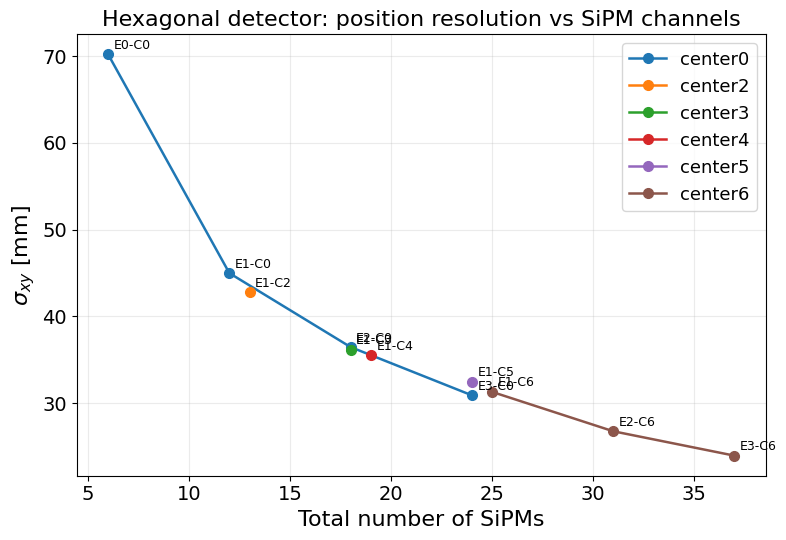

In [5]:
fig, ax = plt.subplots(figsize=(8,5.5))
for center, g in res.groupby("center"):
    ax.plot(g.n_sipm, g.sigma_xy_mm, "o-", lw=1.8, ms=7, label=f"center{center}")
for _, r in res.iterrows():
    ax.annotate(r.config, (r.n_sipm,r.sigma_xy_mm), xytext=(4,4),
                textcoords="offset points", fontsize=9)
ax.set(xlabel="Total number of SiPMs", ylabel=r"$\sigma_{xy}$ [mm]",
       title="Hexagonal detector: position resolution vs SiPM channels")
ax.grid(alpha=.25); ax.legend(ncol=2, fontsize=9)
ax.set_xlabel("Total number of SiPMs", fontsize=FONT)
ax.set_ylabel(r"$\sigma_{xy}$ [mm]", fontsize=FONT)
ax.set_title("Hexagonal detector: position resolution vs SiPM channels",
             fontsize=FONT)
ax.tick_params(labelsize=TICK)
ax.legend(fontsize=LEGEND)
plt.tight_layout(); plt.savefig(OUT/"sigmaXY_vs_nSiPM.png", dpi=180, bbox_inches="tight"); plt.show()

## 4. Relative resolution using the hexagon diagonal

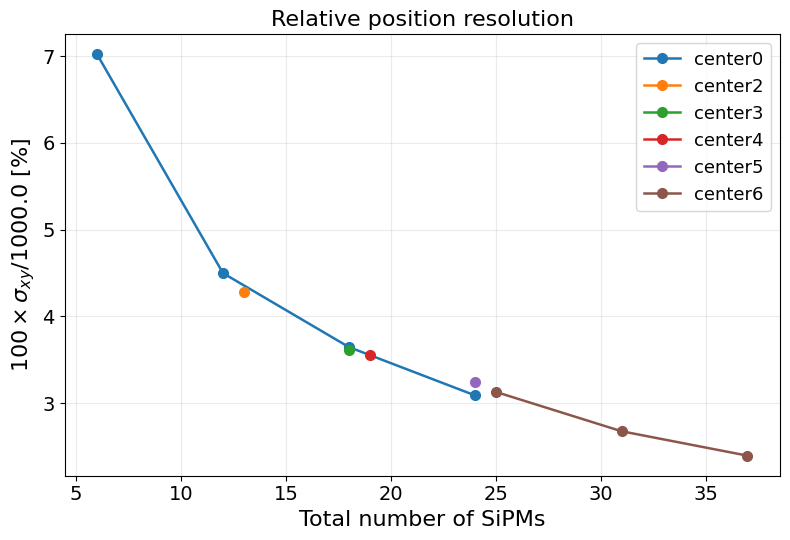

In [6]:
fig, ax = plt.subplots(figsize=(8,5.5))
for center, g in res.groupby("center"):
    ax.plot(g.n_sipm, g.relative_resolution_pct, "o-", lw=1.8, ms=7,
            label=f"center{center}")
ax.set(xlabel="Total number of SiPMs",
       ylabel=rf"$100\times\sigma_{{xy}}/{REFERENCE_LENGTH_MM:.1f}$ [%]",
       title="Relative position resolution")
ax.grid(alpha=.25); ax.legend(ncol=2, fontsize=9)
ax.set_xlabel("Total number of SiPMs", fontsize=FONT)
ax.set_ylabel(
    rf"$100\times\sigma_{{xy}}/{REFERENCE_LENGTH_MM:.1f}$ [%]",
    fontsize=FONT
)
ax.set_title("Relative position resolution", fontsize=FONT)
ax.tick_params(labelsize=TICK)
ax.legend(fontsize=LEGEND)
plt.tight_layout(); plt.savefig(OUT/"relative_resolution_vs_nSiPM.png", dpi=180, bbox_inches="tight"); plt.show()

## 5. Edge × center heatmaps

These make it easy to see whether the improvement comes mainly from adding edge channels or central channels.

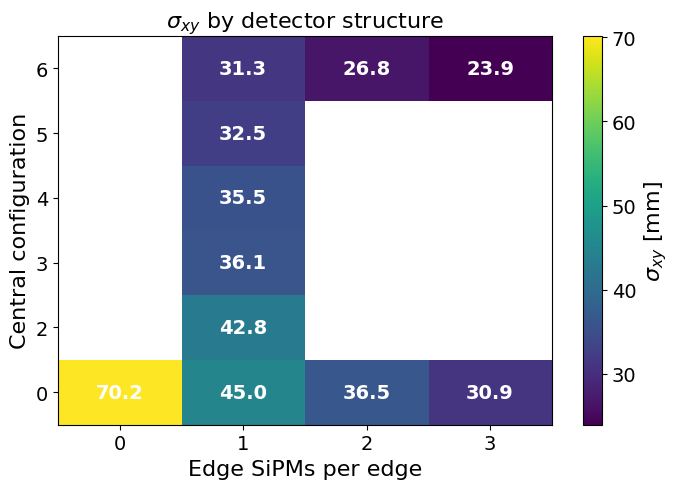

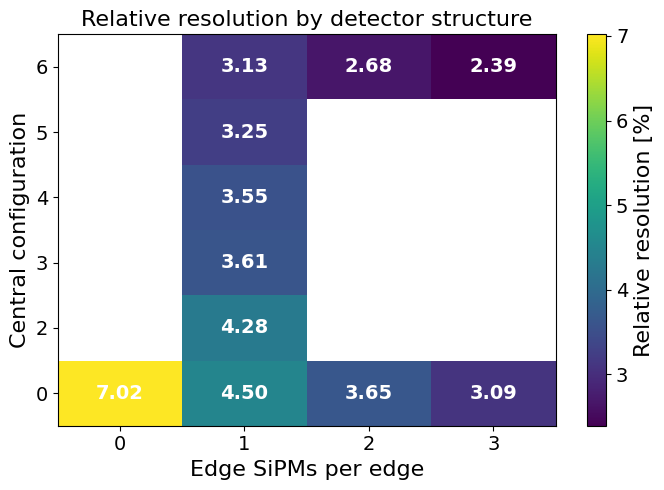

In [7]:
def heatmap(value, title, cbar_label, filename, fmt=".1f"):
    p = res.pivot_table(index="center", columns="edge",
                        values=value, aggfunc="first")

    fig, ax = plt.subplots(figsize=(7,5))
    im = ax.imshow(p.values, origin="lower", aspect="auto")

    ax.set_xticks(range(len(p.columns)), p.columns)
    ax.set_yticks(range(len(p.index)), p.index)
    ax.set_xlabel("Edge SiPMs per edge", fontsize=FONT)
    ax.set_ylabel("Central configuration", fontsize=FONT)
    ax.set_title(title, fontsize=FONT)
    ax.tick_params(labelsize=TICK)

    # White values inside heatmap
    for i in range(len(p.index)):
        for j in range(len(p.columns)):
            v = p.iloc[i,j]
            if np.isfinite(v):
                ax.text(j, i, format(v,fmt),
                        ha="center", va="center",
                        fontsize=14, color="white",
                        fontweight="bold")

    # Larger colorbar text
    cb = plt.colorbar(im, ax=ax)
    cb.set_label(cbar_label, fontsize=FONT)
    cb.ax.tick_params(labelsize=TICK)

    plt.tight_layout()
    plt.savefig(OUT/filename, dpi=180, bbox_inches="tight")
    plt.show()


heatmap(
    "sigma_xy_mm",
    r"$\sigma_{xy}$ by detector structure",
    r"$\sigma_{xy}$ [mm]",
    "heatmap_sigmaXY.png"
)

heatmap(
    "relative_resolution_pct",
    "Relative resolution by detector structure",
    "Relative resolution [%]",
    "heatmap_relative_resolution.png",
    ".2f"
)

## 6. Separate edge-SiPM and central-SiPM trends

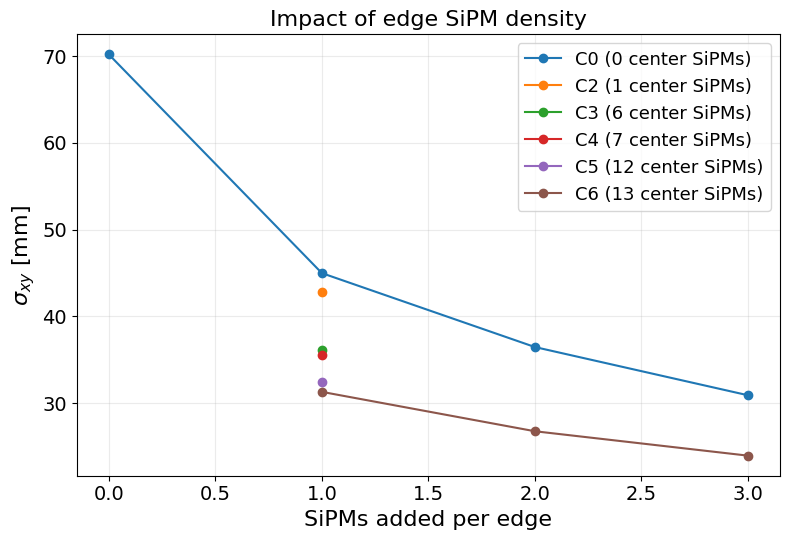

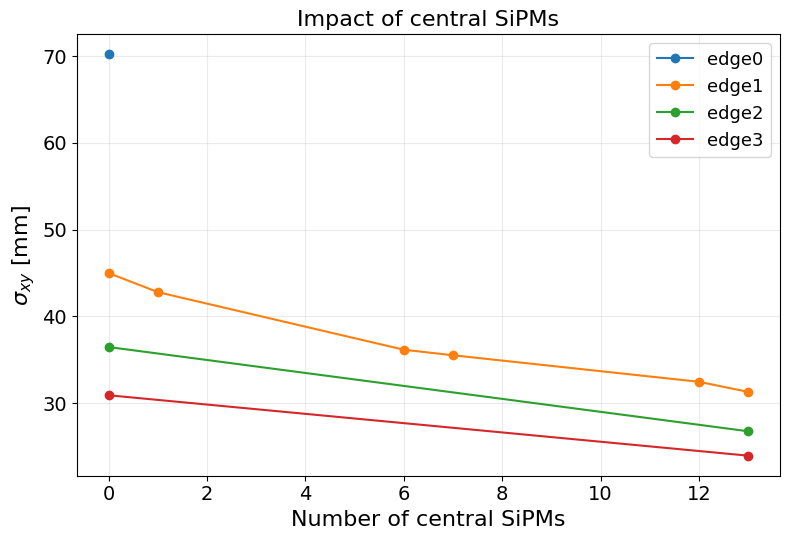

In [8]:
fig, ax = plt.subplots(figsize=(8,5.5))
for center,g in res.groupby("center"):
    g=g.sort_values("edge")
    ax.plot(g.edge,g.sigma_xy_mm,"o-",label=f"C{center} ({int(g.n_center.iloc[0])} center SiPMs)")
# ax.set(xlabel="SiPMs added per edge",ylabel=r"$\sigma_{xy}$ [mm]",
#        title="Impact of edge SiPM density")
ax.grid(alpha=.25); ax.legend(fontsize=9)
ax.set_xlabel("SiPMs added per edge", fontsize=FONT)
ax.set_ylabel(r"$\sigma_{xy}$ [mm]", fontsize=FONT)
ax.set_title("Impact of edge SiPM density", fontsize=FONT)
ax.tick_params(labelsize=TICK)
ax.legend(fontsize=LEGEND)
plt.tight_layout(); plt.savefig(OUT/"edge_impact.png",dpi=180,bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8,5.5))
for edge,g in res.groupby("edge"):
    g=g.sort_values("n_center")
    ax.plot(g.n_center,g.sigma_xy_mm,"o-",label=f"edge{edge}")
# ax.set(xlabel="Number of central SiPMs",ylabel=r"$\sigma_{xy}$ [mm]",
#        title="Impact of central SiPMs")
ax.grid(alpha=.25); ax.legend(fontsize=9)
ax.set_xlabel("Number of central SiPMs", fontsize=FONT)
ax.set_ylabel(r"$\sigma_{xy}$ [mm]", fontsize=FONT)
ax.set_title("Impact of central SiPMs", fontsize=FONT)
ax.tick_params(labelsize=TICK)
ax.legend(fontsize=LEGEND)
plt.tight_layout(); plt.savefig(OUT/"center_impact.png",dpi=180,bbox_inches="tight"); plt.show()

## 7. Improvement per additional SiPM

The next table is useful for judging diminishing returns. It compares neighboring points **within each center configuration** as the edge density increases.

In [9]:
inc = []
for center,g in res.groupby("center"):
    g=g.sort_values("n_sipm").reset_index(drop=True)
    for i in range(1,len(g)):
        a,b=g.iloc[i-1],g.iloc[i]
        dn=b.n_sipm-a.n_sipm
        ds=a.sigma_xy_mm-b.sigma_xy_mm
        inc.append(dict(center=center,from_config=a.config,to_config=b.config,
                        added_sipm=dn,improvement_mm=ds,
                        improvement_per_added_sipm_mm=ds/dn if dn else np.nan))
inc = pd.DataFrame(inc)
if not inc.empty:
    inc.to_csv(OUT/"incremental_improvement.csv",index=False)
display(inc.round(3))

,center,from_config,to_config,added_sipm,improvement_mm,improvement_per_added_sipm_mm
0,0,E0-C0,E1-C0,6,25.210,4.202
1,0,E1-C0,E2-C0,6,8.521,1.420
2,0,E2-C0,E3-C0,6,5.557,0.926
3,6,E1-C6,E2-C6,6,4.540,0.757
4,6,E2-C6,E3-C6,6,2.812,0.469


## 8. Compare the timing-jitter scans

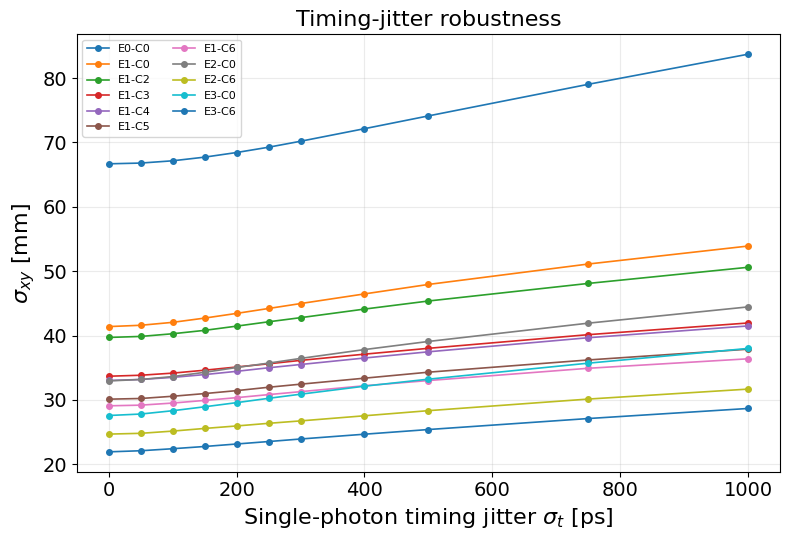

,config,n_sipm,sigma_t_ps,sigma_xy_mm
6,E0-C0,6,300,70.19
17,E1-C0,12,300,44.98
28,E1-C2,13,300,42.78
39,E1-C3,18,300,36.15
83,E2-C0,18,300,36.45
50,E1-C4,19,300,35.51
61,E1-C5,24,300,32.45
105,E3-C0,24,300,30.90
72,E1-C6,25,300,31.29
94,E2-C6,31,300,26.75


In [10]:
timing_rows = []
timing_names = ["true_detector_timing_resolution_scan.csv",
                "true_detector_timing_resolution_scan_summary.csv"]

for c in configs:
    f = find_file(c["folder"], timing_names)
    df = read_csv_clean(f) if f else None
    if df is None or df.empty: continue
    tcol = first_col(df, ["sigma_t_ps","timing_sigma_ps","sigma_ps"])
    scol = first_col(df, ["sigma_xy_mm","sigma_xy","sxy_mm","sxy"])
    if not tcol or not scol: continue
    x = pd.to_numeric(df[tcol],errors="coerce")
    y = pd.to_numeric(df[scol],errors="coerce")
    for xx,yy in zip(x,y):
        if np.isfinite(xx) and np.isfinite(yy):
            timing_rows.append({**{k:c[k] for k in ["config","edge","center","n_sipm"]},
                                "sigma_t_ps":xx,"sigma_xy_mm":yy})

timing = pd.DataFrame(timing_rows)
if not timing.empty:
    fig,ax=plt.subplots(figsize=(8,5.5))
    for name,g in timing.groupby("config"):
        ax.plot(g.sigma_t_ps,g.sigma_xy_mm,"o-",ms=4,lw=1.2,label=name)
    # ax.set(xlabel=r"Single-photon timing jitter $\sigma_t$ [ps]",
    #        ylabel=r"$\sigma_{xy}$ [mm]",title="Timing-jitter robustness")
    ax.grid(alpha=.25)
    ax.set_xlabel(
        r"Single-photon timing jitter $\sigma_t$ [ps]",
        fontsize=FONT
    )
    ax.set_ylabel(r"$\sigma_{xy}$ [mm]", fontsize=FONT)
    ax.set_title("Timing-jitter robustness", fontsize=FONT)
    ax.tick_params(labelsize=TICK)

    if timing.config.nunique() <= 12: ax.legend(fontsize=8,ncol=2)
    plt.tight_layout(); plt.savefig(OUT/"timing_jitter_comparison.png",dpi=180,bbox_inches="tight"); plt.show()

    # Comparison at the normal 300 ps working point: nearest available scan point
    at300=[]
    for name,g in timing.groupby("config"):
        r=g.iloc[np.argmin(np.abs(g.sigma_t_ps.to_numpy()-300))]
        at300.append(r)
    at300=pd.DataFrame(at300).sort_values("n_sipm")
    display(at300[["config","n_sipm","sigma_t_ps","sigma_xy_mm"]].round(2))
else:
    print("No readable timing-scan CSVs found.")

## 9. Optional: visual comparison of saved spatial-resolution maps

This cell creates contact sheets from `spatial_resolution_map_best.png`.
It is useful for checking **where** the resolution improves, not only the global number.

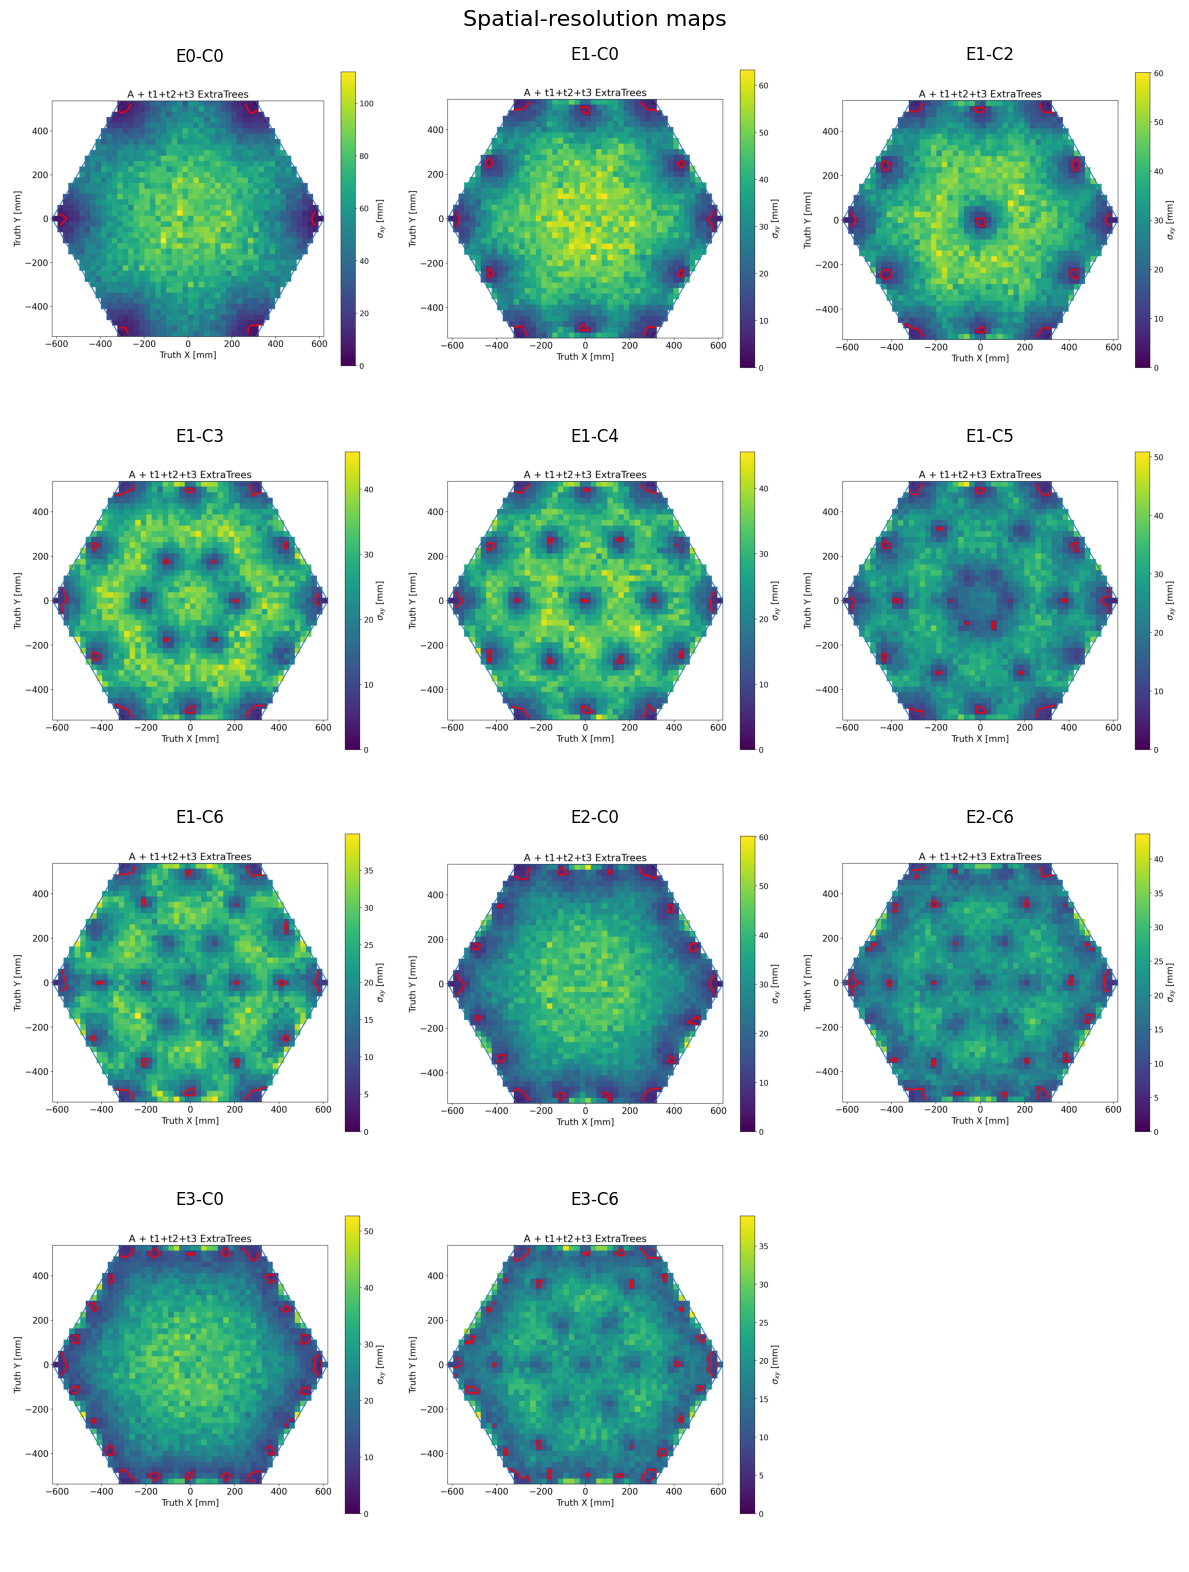

In [11]:
from math import ceil

maps=[]
for c in configs:
    p=c["folder"]/"spatial_resolution_map_best.png"
    if p.exists(): maps.append((c["config"],p))

if maps:
    for start in range(0,len(maps),12):
        part=maps[start:start+12]; ncol=3; nrow=ceil(len(part)/ncol)
        fig,axs=plt.subplots(nrow,ncol,figsize=(12,4*nrow))
        axs=np.atleast_1d(axs).ravel()
        for ax,(name,p) in zip(axs,part):
            ax.imshow(plt.imread(p)); ax.set_title(name,fontsize=12); ax.axis("off")
        for ax in axs[len(part):]: ax.axis("off")
        fig.suptitle("Spatial-resolution maps",fontsize=16)
        plt.tight_layout()
        plt.savefig(OUT/f"spatial_maps_{start//12+1}.png",dpi=150,bbox_inches="tight")
        plt.show()
else:
    print("No spatial_resolution_map_best.png files found.")

## 10. Compact final summary

In [12]:
show = res[["config","edge","center","n_center","n_sipm",
            "sigma_x_mm","sigma_y_mm","sigma_xy_mm","relative_resolution_pct"]].copy()
show = show.sort_values(["sigma_xy_mm","n_sipm"], na_position="last")
display(show.round(3))

print(f"\nResults saved to: {OUT}")
print("Reference length used:", REFERENCE_LENGTH_MM, "mm")

,config,edge,center,n_center,n_sipm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,relative_resolution_pct
10,E3-C6,3,6,13,37,23.948,23.929,23.938,2.394
9,E2-C6,2,6,13,31,26.853,26.648,26.751,2.675
7,E3-C0,3,0,0,24,31.179,30.614,30.898,3.090
8,E1-C6,1,6,13,25,31.348,31.234,31.291,3.129
6,E1-C5,1,5,12,24,32.535,32.372,32.454,3.245
5,E1-C4,1,4,7,19,35.423,35.595,35.509,3.551
3,E1-C3,1,3,6,18,36.178,36.118,36.148,3.615
4,E2-C0,2,0,0,18,36.509,36.401,36.455,3.646
2,E1-C2,1,2,1,13,42.917,42.652,42.785,4.278
1,E1-C0,1,0,0,12,44.889,45.063,44.976,4.498



Results saved to: /Volumes/ExtremeSSD/Software/FlashPointHexShape/run/BulkProduction/comparison_summary
Reference length used: 999.9947785549881 mm
